# v6 — Cabang sinyal EKG mentah 50 Hz

**Pertanyaan.** v3–v5 menunjukkan semua cara yang hanya memakai interval RR berhenti di Macro-F1 ±0,83, dan pasien
07910, 08215, 06426 tidak pernah terdeteksi. Apakah **bentuk gelombang EKG** (aktivitas atrium; gelombang flutter 4–6 Hz masih
di bawah Nyquist 25 Hz) menambah informasi?

| Varian | Input | Hipotesis (ditetapkan sebelum melihat hasil) |
|---|---|---|
| **6a. CNN EKG saja** | potongan EKG 10 s @50 Hz (500 sampel) | Morfologi saja sudah memuat info AFL (baseline; menggantikan MiniRocket yang tidak terpasang) |
| **6b. Dua cabang EKG + RR** (utama) | CNN EKG + badan MicroTransformer (cabang RR v2), digabung | Lebih baik dari v3.1, terutama recall AFL pada pasien yang gagal di semua versi RR |
| Late fusion (eksploratif) | rata-rata probabilitas v3.1 dan 6a | — |

**Agar adil.** Fold, seed latih, dan window uji identik dengan referensi v3.1; bias cross-fit grid −7…+3; metrik window & episode
memakai kode v4. Resep: bobot kelas lunak (bawaan sejak v5), 30 epoch, AdamW, cosine; EKG dibandpass 0,5–20 Hz lalu
distandardisasi per window; augmentasi polaritas acak (lead perangkat bisa terbalik).

Biaya: 2 model × 5 ulangan × 5 fold (±2 jam GPU, bisa dilanjutkan). Tidak menyentuh paket produksi. Logika di `ekg.py`.

In [1]:
import json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import ekg as K
cv = K.cv
pd.set_option("display.width", 230)
pd.set_option("display.max_columns", 30)


def fmt(v, nd=3):
    return f"{v[0]:.{nd}f} [{v[1]:.2f}–{v[2]:.2f}]"


def verdict(p):
    return "lebih baik" if p >= .95 else "lebih buruk" if p <= .05 else "tidak terbedakan"

## 1. Potongan EKG per window

Diambil dari sinyal yang sama dengan detektor R-peak v2 (lead 0, resample 50 Hz), lalu dibandpass. **Bukti sejajar:** jumlah
R-peak di dalam tiap potongan harus sama dengan jumlah IBI window yang sama di dataset v2.

✓ 165,978 potongan EKG, semuanya sejajar dengan interval RR (35s)


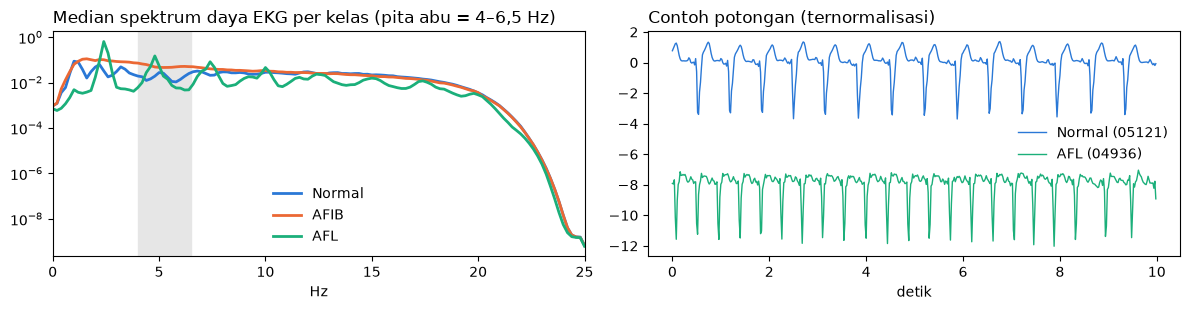

{'Normal': 0.103, 'AFIB': 0.19, 'AFL': 0.156} = porsi daya 4–6,5 Hz


In [2]:
t0 = time.perf_counter()
info = K.build_ecg_windows()
assert info["mismatch"] == 0, info
print(f"✓ {info['n']:,} potongan EKG, semuanya sejajar dengan interval RR ({time.perf_counter() - t0:.0f}s)")

f, spec = K.class_spectra()
std = np.load(K.DATA_STD)
E = np.load(K.ECG_FILE)["ecg"]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
for c, col in zip(("Normal", "AFIB", "AFL"), ("#2a78d6", "#eb6834", "#1baf7a")):
    axes[0].semilogy(f, spec[c], color=col, lw=2, label=c)
axes[0].axvspan(4, 6.5, color="0.9"); axes[0].set_xlim(0, 25); axes[0].set_xlabel("Hz")
axes[0].set_title("Median spektrum daya EKG per kelas (pita abu = 4–6,5 Hz)", loc="left"); axes[0].legend(frameon=False)
rng = np.random.default_rng(1)
for c, col, off in ((0, "#2a78d6", 0), (2, "#1baf7a", -8)):
    i = rng.choice(np.flatnonzero(std["y"] == c))
    axes[1].plot(np.arange(500) / 50, E[i].astype(float) + off, color=col, lw=1,
                 label=f"{['Normal', 'AFIB', 'AFL'][c]} ({std['records'][i]})")
axes[1].set_title("Contoh potongan (ternormalisasi)", loc="left"); axes[1].set_xlabel("detik"); axes[1].legend(frameon=False)
plt.tight_layout(); plt.show()
band, ref = (f >= 4) & (f <= 6.5), (f >= 1) & (f <= 20)
print({c: round(float(p[band].sum() / p[ref].sum()), 3) for c, p in spec.items()}, "= porsi daya 4–6,5 Hz")

## 2. Training (2 model × 5 ulangan × 5 fold)

OOF → `../cache/oof_robust/detector_e30_r5_s2026/{EKG_CNN, EKG_RR_DualBranch}_r{ulangan}.npz`. Job yang sudah ada dilewati.

In [3]:
for kind in K.MODELS:
    print(f"{K.MODELS[kind]}: {sum(p.numel() for p in K.build(kind).parameters()):,} parameter")
K.run_all_jobs()

6a: CNN EKG saja: 390,051 parameter
6b: dua cabang EKG + RR: 416,710 parameter
10 job tersisa


  [ 11.2 mnt] ekg   ulangan 0: 132 s/fold


  [ 24.5 mnt] dual  ulangan 0: 159 s/fold


  [ 35.6 mnt] ekg   ulangan 1: 132 s/fold


  [ 49.0 mnt] dual  ulangan 1: 159 s/fold


...

  [ 73.4 mnt] dual  ulangan 2: 160 s/fold


  [ 84.5 mnt] ekg   ulangan 3: 132 s/fold


  [ 98.2 mnt] dual  ulangan 3: 163 s/fold


  [109.2 mnt] ekg   ulangan 4: 131 s/fold


  [122.4 mnt] dual  ulangan 4: 157 s/fold


## 3. Hasil

In [4]:
res = K.evaluate()
lab = res["labels"]
order = ["v1", "v31", "ekg", "dual", "late"]
RES = pd.DataFrame([{"Varian": lab[k], **{m: fmt(res["rows"][k][m]) for m in ("Macro-F1", "AFL F1", "AFL P", "AFL R", "Normal R", "AFIB F1")},
                     "alarm AFL palsu/jam": fmt(res["episodes"][k]["alarm/jam"]),
                     "deteksi episode": fmt(res["episodes"][k]["deteksi episode"], 2)} for k in order]).set_index("Varian")
display(RES)
ref_v3 = pd.read_csv(K.OOF_DIR / "ringkasan.csv").set_index("Model").loc["MicroTransformer +bias", "Macro-F1"]
assert ref_v3.startswith(f"{res['rows']['v31']['Macro-F1'][0]:.3f}"), ref_v3
print("✓ Referensi identik dengan v3/v3.1:", ref_v3)

PAIR = pd.DataFrame([{"Varian": lab[k], **{f"Δ {m}": f"{v[0]:+.3f} [{v[1]:+.2f}…{v[2]:+.2f}]" for m, v in res["pairs"][k].items()
                                            if m in ("Macro-F1", "AFL F1", "AFL R", "AFL P", "Normal R", "deteksi episode")},
                      "P(Δ MF1>0)": round(res["pairs"][k]["Macro-F1"][3], 2), "vonis": verdict(res["pairs"][k]["Macro-F1"][3])}
                     for k in ("v1", "ekg", "dual", "late")]).set_index("Varian")
print("Δ berpasangan terhadap v3.1")
display(PAIR)

,Macro-F1,AFL F1,AFL P,AFL R,Normal R,AFIB F1,alarm AFL palsu/jam,deteksi episode
Varian,,,,,,,,
"v1 (sebelum revisi), argmax",0.744 [0.64–0.81],0.399 [0.09–0.59],0.275 [0.05–0.46],0.728 [0.37–0.98],0.903 [0.82–0.95],0.898 [0.85–0.93],5.101 [2.69–7.89],0.91 [0.73–1.00]
v3.1 referensi (RR saja),0.832 [0.67–0.92],0.647 [0.17–0.89],0.715 [0.26–0.95],0.592 [0.13–0.91],0.924 [0.84–0.97],0.909 [0.86–0.94],0.512 [0.10–1.07],0.74 [0.42–0.93]
6a: CNN EKG saja,0.651 [0.52–0.77],0.380 [0.12–0.57],0.418 [0.11–0.93],0.432 [0.18–0.57],0.751 [0.58–0.91],0.763 [0.65–0.87],1.646 [0.11–4.48],0.71 [0.27–0.91]
6b: dua cabang EKG + RR,0.747 [0.57–0.83],0.583 [0.15–0.70],0.618 [0.16–0.90],0.563 [0.16–0.67],0.800 [0.66–0.93],0.808 [0.72–0.90],1.025 [0.17–2.35],0.74 [0.40–0.91]
Late fusion v3.1 + CNN EKG (eksploratif),0.838 [0.70–0.89],0.632 [0.24–0.76],0.795 [0.35–0.91],0.536 [0.19–0.76],0.965 [0.94–0.98],0.927 [0.90–0.95],0.360 [0.15–0.60],0.75 [0.36–0.94]


✓ Referensi identik dengan v3/v3.1: 0.832 [0.67–0.92]
Δ berpasangan terhadap v3.1


,Δ Macro-F1,Δ AFL F1,Δ AFL P,Δ AFL R,Δ Normal R,Δ deteksi episode,P(Δ MF1>0),vonis
Varian,,,,,,,,
"v1 (sebelum revisi), argmax",-0.088 [-0.16…-0.02],-0.249 [-0.47…-0.05],-0.440 [-0.65…-0.22],+0.136 [+0.06…+0.24],-0.020 [-0.03…-0.01],+0.169 [+0.03…+0.42],0.02,lebih buruk
6a: CNN EKG saja,-0.181 [-0.32…-0.04],-0.267 [-0.58…+0.04],-0.297 [-0.69…+0.27],-0.160 [-0.43…+0.08],-0.172 [-0.36…+0.02],-0.031 [-0.14…+0.03],0.00,lebih buruk
6b: dua cabang EKG + RR,-0.084 [-0.23…+0.02],-0.065 [-0.39…+0.14],-0.097 [-0.51…+0.18],-0.029 [-0.37…+0.13],-0.124 [-0.28…+0.04],+0.000 [-0.05…+0.04],0.07,tidak terbedakan
Late fusion v3.1 + CNN EKG (eksploratif),+0.006 [-0.05…+0.05],-0.015 [-0.16…+0.08],+0.080 [-0.21…+0.21],-0.056 [-0.19…+0.09],+0.041 [+0.00…+0.11],+0.015 [-0.06…+0.07],0.62,tidak terbedakan


In [5]:
AFL = pd.DataFrame({lab[k]: res["afl_recall"][k] for k in order}, index=res["afl_patients"]).round(2)
AFL.index.name = "recall AFL per pasien"
display(AFL)
display(pd.DataFrame({lab[k]: v for k, v in res["fp"].items()}).T.round(0).rename(
    columns={"total": "AFL palsu (window/ulangan)", "pasien_lain": "di pasien tanpa AFL"}))
display(pd.DataFrame({lab[k]: {"bias AFIB (median)": v["median"][1], "bias AFL (median)": v["median"][2],
                               "bias AFL rentang": f"{v['min'][2]:.2f} … {v['max'][2]:.2f}"} for k, v in res["bias"].items()}).T)

,"v1 (sebelum revisi), argmax",v3.1 referensi (RR saja),6a: CNN EKG saja,6b: dua cabang EKG + RR,Late fusion v3.1 + CNN EKG (eksploratif)
recall AFL per pasien,,,,,
04043,1.00,0.40,0.00,0.40,0.20
04908,1.00,0.92,1.00,1.00,1.00
04936,0.67,0.51,0.45,0.64,0.50
06426,0.73,0.17,0.44,0.29,0.49
07910,0.21,0.00,0.00,0.00,0.00
08215,0.04,0.00,0.00,0.00,0.00
08378,1.00,0.96,0.46,0.53,0.73


,AFL palsu (window/ulangan),di pasien tanpa AFL
"v1 (sebelum revisi), argmax",2240.0,1059.0
v3.1 referensi (RR saja),274.0,25.0
6a: CNN EKG saja,1160.0,25.0
6b: dua cabang EKG + RR,464.0,7.0
Late fusion v3.1 + CNN EKG (eksploratif),156.0,12.0


,bias AFIB (median),bias AFL (median),bias AFL rentang
v3.1 referensi (RR saja),-0.75,-4.5,-5.50 … -4.00
6a: CNN EKG saja,-1.75,-1.5,-7.00 … 3.00
6b: dua cabang EKG + RR,-3.75,-4.75,-7.00 … 1.50
Late fusion v3.1 + CNN EKG (eksploratif),-0.25,-1.0,-4.25 … -0.25


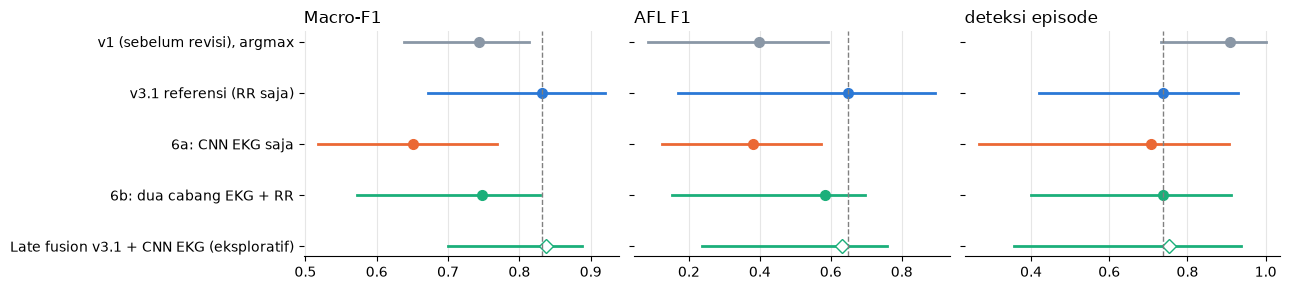

In [6]:
COLOR = {"v1": "#8A97A6", "v31": "#2a78d6", "ekg": "#eb6834", "dual": "#1baf7a", "late": "#1baf7a"}
fig, axes = plt.subplots(1, 3, figsize=(13, 3), sharey=True)
for ax, (m, src) in zip(axes, (("Macro-F1", "rows"), ("AFL F1", "rows"), ("deteksi episode", "episodes"))):
    for i, k in enumerate(order):
        pt, lo, hi = res[src][k][m]
        ax.plot([lo, hi], [i, i], color=COLOR[k], lw=2)
        ax.plot(pt, i, "o" if k != "late" else "D", color=COLOR[k], mfc="white" if k == "late" else COLOR[k], ms=7)
    ax.axvline(res[src]["v31"][m][0], color="0.5", lw=1, ls="--")
    ax.set_title(m, loc="left"); ax.grid(axis="x", color="0.9"); ax.set_axisbelow(True)
    for s_ in ("top", "right", "left"):
        ax.spines[s_].set_visible(False)
axes[0].set_yticks(range(len(order)), [lab[k] for k in order]); axes[0].invert_yaxis()
plt.tight_layout(); plt.show()

In [7]:
K.CACHE_OUT.mkdir(parents=True, exist_ok=True)
res["spectra"] = {"f": f.tolist(), **{c: p.tolist() for c, p in spec.items()}}
(K.CACHE_OUT / "ringkasan.json").write_text(json.dumps(res, indent=1, ensure_ascii=False))
for k in ("ekg", "dual", "late"):
    p = res["pairs"][k]
    print(f"{lab[k]:<42} Δ Macro-F1 {p['Macro-F1'][0]:+.3f} (P={p['Macro-F1'][3]:.2f}, {verdict(p['Macro-F1'][3])}) | "
          f"Δ AFL F1 {p['AFL F1'][0]:+.3f} | Δ AFL R {p['AFL R'][0]:+.3f}")
print(f"Ringkasan → {K.CACHE_OUT.relative_to(K.REPO)}/ringkasan.json")

6a: CNN EKG saja                           Δ Macro-F1 -0.181 (P=0.00, lebih buruk) | Δ AFL F1 -0.267 | Δ AFL R -0.160
6b: dua cabang EKG + RR                    Δ Macro-F1 -0.084 (P=0.07, tidak terbedakan) | Δ AFL F1 -0.065 | Δ AFL R -0.029
Late fusion v3.1 + CNN EKG (eksploratif)   Δ Macro-F1 +0.006 (P=0.62, tidak terbedakan) | Δ AFL F1 -0.015 | Δ AFL R -0.056
Ringkasan → cache/v6/ringkasan.json


## 4. Kesimpulan

**Bentuk gelombang EKG 50 Hz belum memperbaiki sistem. Paket produksi tetap v3.1; v6 tidak dikemas.**

- **Data.**
  - 165.978 potongan EKG dibuktikan sejajar dengan interval RR (tidak ada selisih jumlah R-peak).
  - AFL/AFIB punya porsi daya 4–6,5 Hz lebih besar dari Normal (0,156 / 0,190 vs 0,103). Tetapi puncak AFL di ±2,5, 5, 7,5 Hz
    sebagian besar adalah kelipatan laju ventrikel ±150 bpm (konduksi 2:1), bukan gelombang flutter murni.
- **6a, CNN EKG saja: lebih buruk.** Macro-F1 0,651 vs 0,832 (Δ −0,181, P = 0,00); recall Normal 0,751. Ada info AFL
  (06426: 0,17 → 0,44), tapi tidak cukup sendirian.
- **6b, dua cabang EKG + RR: hipotesis ditolak.**
  - Macro-F1 0,747 (Δ −0,084, P = 0,07, cenderung lebih buruk); recall Normal turun ke 0,800.
  - Cabang EKG yang besar overfit per pasien: bias antar fold melompat −7…+1,5.
- **Late fusion (eksploratif): setara** (Δ +0,006, P = 0,62).
  - Recall Normal naik konsisten (+0,041), AFL palsu 274 → 156, 06426 0,17 → 0,49.
  - Tetapi 08378 turun (0,96 → 0,73). Kandidat yang perlu dikonfirmasi pada data lain.
- **07910 dan 08215 tetap 0** pada semua model, termasuk yang melihat bentuk gelombang.

**Untuk proyek.** v3–v6 sudah menghabiskan tuas model, kalibrasi, pasca-proses, resep training, dan input bentuk gelombang. Batasnya
adalah jumlah pasien: 7 pasien AFL, 23 total.

**Langkah berikutnya (v7):** data dengan lebih banyak pasien AFL, misalnya basis data 12-lead Chapman–Shaoxing (PhysioNet,
rekaman 10 s), untuk training dan uji eksternal. Butuh persetujuan pemilik repo untuk mengunduh.